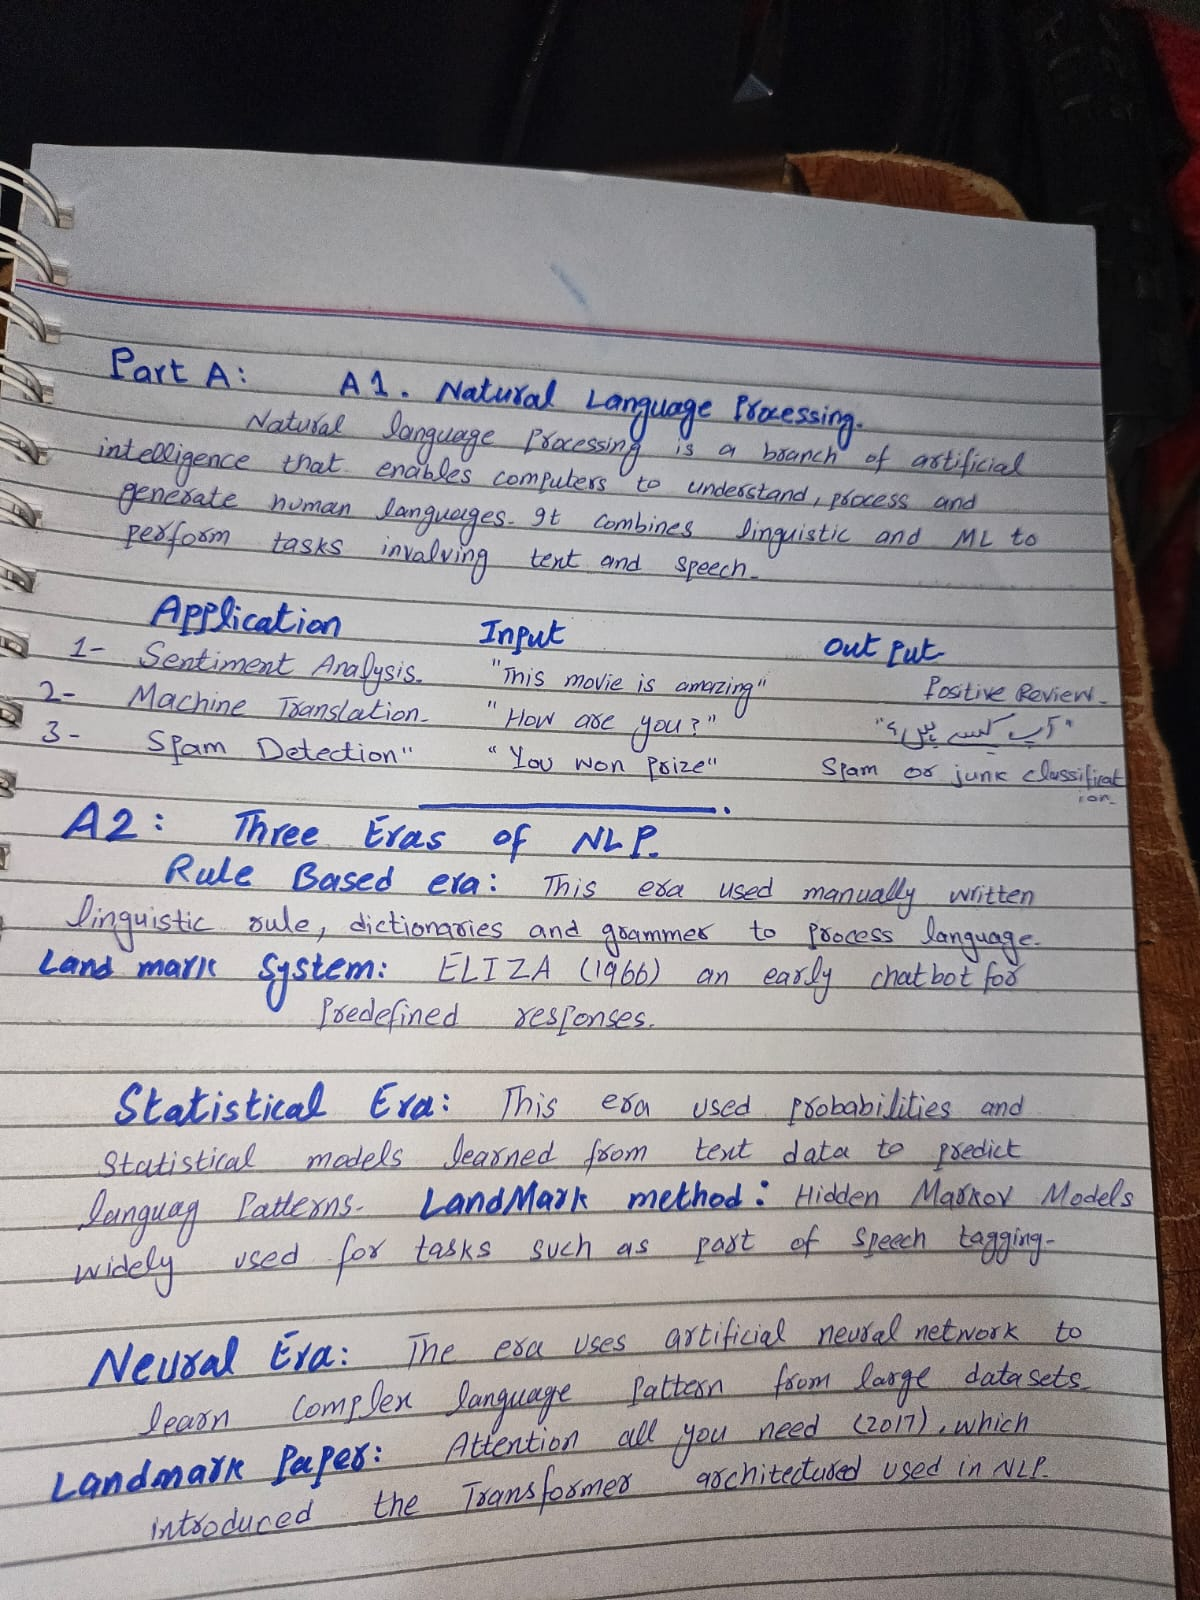

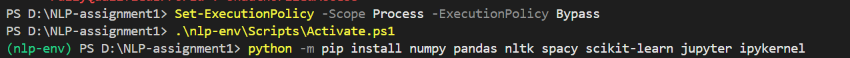

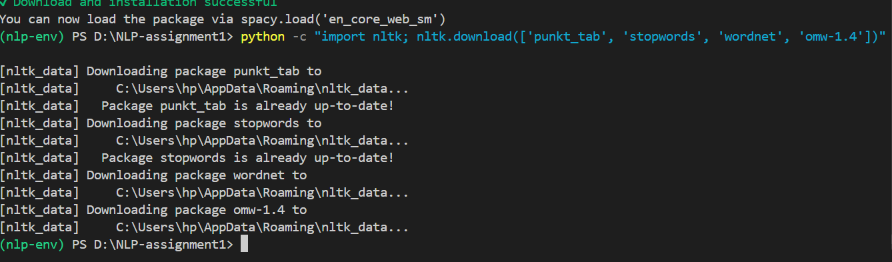

In [1]:
import sys
import numpy as np
import pandas as pd
import nltk
import spacy
import sklearn

print("Python Version:", sys.version.split()[0])
print("NumPy Version:", np.__version__)
print("Pandas Version:", pd.__version__)
print("NLTK Version:", nltk.__version__)
print("spaCy Version:", spacy.__version__)
print("Scikit-learn Version:", sklearn.__version__)

Python Version: 3.12.4
NumPy Version: 2.5.4
Pandas Version: 3.0.6
NLTK Version: 3.10.3
spaCy Version: 3.8.16
Scikit-learn Version: 1.9.1



###  Why Is a Virtual Environment Better Than Global Installation?

A virtual environment creates an isolated space for each Python project, allowing us to install libraries without affecting the global Python installation. It prevents dependency and version conflicts between different projects. It also makes projects easier to manage, share, and reproduce.


## B1

In [3]:
import string
from collections import Counter

D1 = "The cat sat on the mat."
D2 = "The dog chased the cat."
D3 = "Dogs and cats are friendly pets."

def word_freq(text):

    text = text.lower()

    text = text.translate(str.maketrans("", "", string.punctuation))

    words = text.split()

    freq = {}

    for word in words:
        if word in freq:
            freq[word] += 1
        else:
            freq[word] = 1

    return freq



combined_text = D1 + " " + D2 + " " + D3

frequencies = word_freq(combined_text)

print("Word Frequencies:")
print(frequencies)

top_3 = Counter(frequencies).most_common(3)

print("\nTop 3 Most Frequent Words:")

for word, count in top_3:
    print(word, ":", count)


Word Frequencies:
{'the': 4, 'cat': 2, 'sat': 1, 'on': 1, 'mat': 1, 'dog': 1, 'chased': 1, 'dogs': 1, 'and': 1, 'cats': 1, 'are': 1, 'friendly': 1, 'pets': 1}

Top 3 Most Frequent Words:
the : 4
cat : 2
sat : 1



### Explanation of Results

The word_freq() function successfully calculates the frequency of each word in the combined documents.
The function uses a Python dictionary for counting word occurrences without using Counter inside the function. The Counter.most_common(3) method is used outside the function to find the three most frequent words.
stemming and lemmatization is not applied.

## B2

In [4]:
a = np.array([1, 2, 3])
b = np.array([2, 0, 1])

dot_product = np.dot(a, b)

# Euclidean (L2) norm of each vector
norm_a = np.linalg.norm(a)
norm_b = np.linalg.norm(b)

# cosine similarity
cosine_similarity = dot_product / (norm_a * norm_b)

print("Vector a:", a)
print("Vector b:", b)

print("\nDot Product:", dot_product)
print("L2 Norm of a:", round(norm_a, 4))
print("L2 Norm of b:", round(norm_b, 4))
print("Cosine Similarity:", round(cosine_similarity, 4))


Vector a: [1 2 3]
Vector b: [2 0 1]

Dot Product: 5
L2 Norm of a: 3.7417
L2 Norm of b: 2.2361
Cosine Similarity: 0.5976


### Calculation of cosine similarity on paper

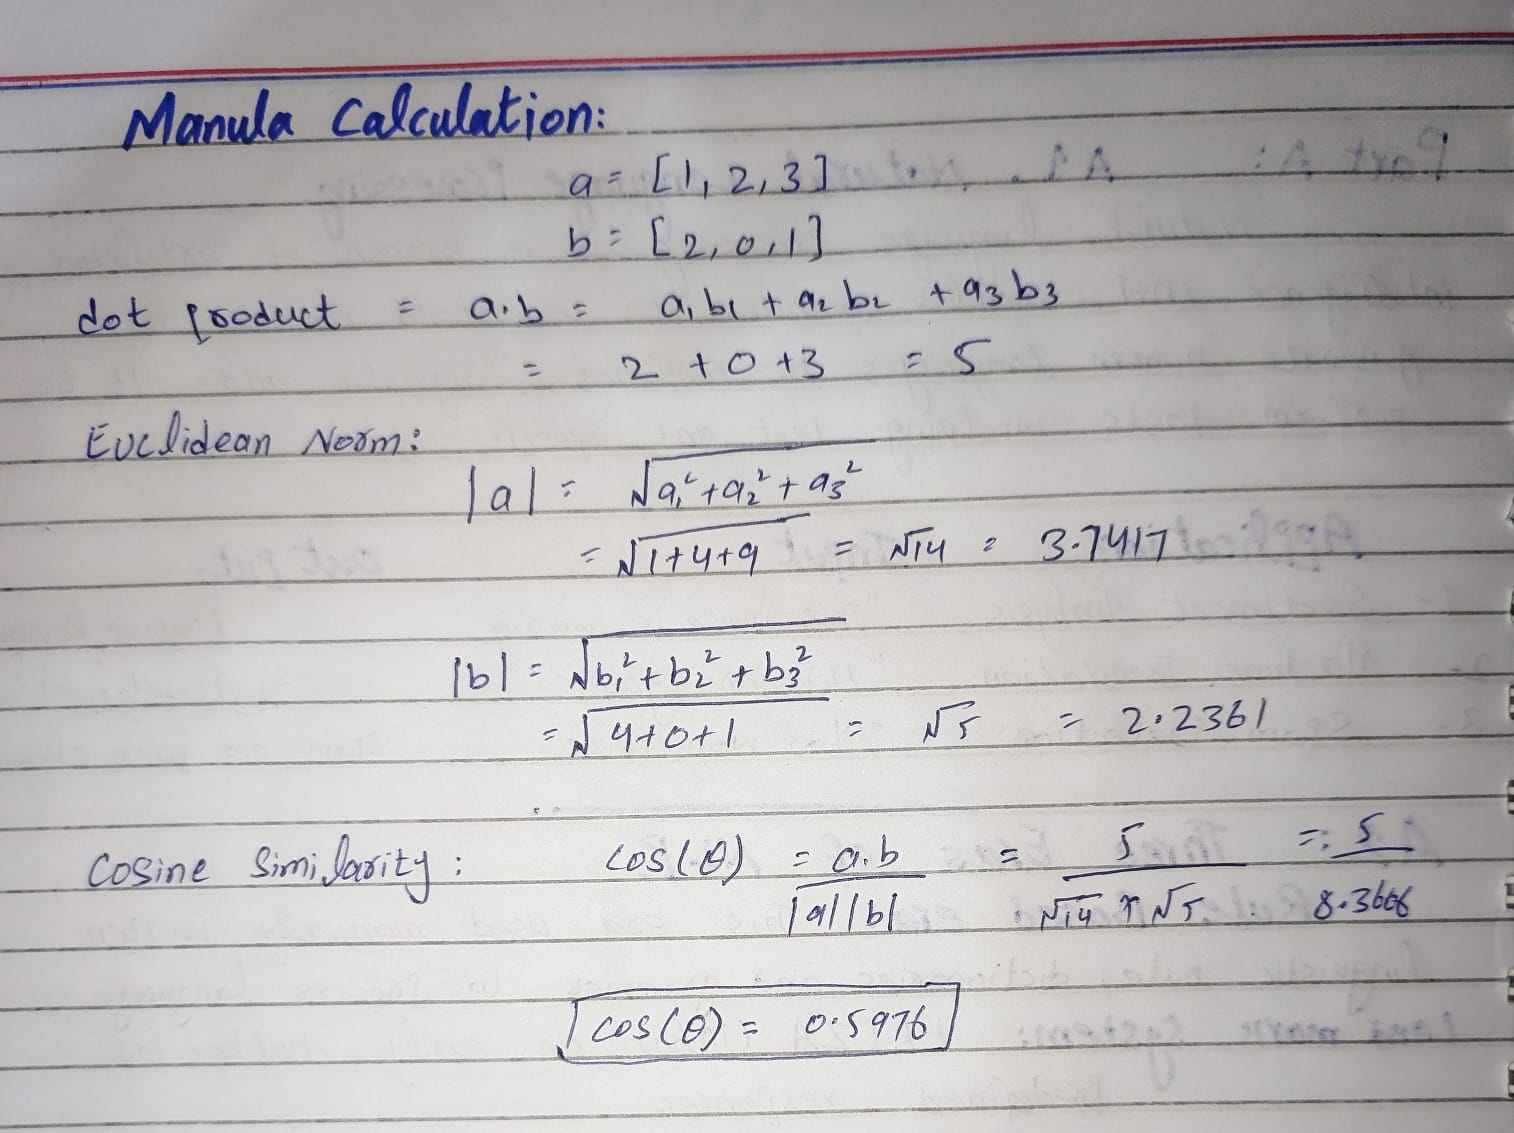

### Result and Verification
The dot product of vectors a and b is **5** while their Euclidean norms are **3.7417** and **2.2361** respectively.
The cosine similarity calculated using NumPy is **0.5976**which matches the manually calculated value of **0.5976**.
both methods produce the same result confirming that the calculations are correct.


## B3

In [5]:
D1 = "The cat sat on the mat."
D2 = "The dog chased the cat."
D3 = "Dogs and cats are friendly pets."
# DataFrame
data = {
    "doc_id": ["D1", "D2", "D3"],
    "text": [D1, D2, D3]
}

df = pd.DataFrame(data)

print("Original DataFrame:")
display(df)

# number of words and characters
df["n_words"] = df["text"].str.split().str.len()
df["n_chars"] = df["text"].str.len()

print("DataFrame with word and character counts:")
display(df)

#documents with more than 5 words
filtered_df = df[df["n_words"] > 5]

print("Documents with More Than 5 Words:")
display(filtered_df)

# mean word count
mean_words = df["n_words"].mean()

print("Mean Number of Words:", round(mean_words, 2))

Original DataFrame:


,doc_id,text
0,D1,The cat sat on the mat.
1,D2,The dog chased the cat.
2,D3,Dogs and cats are friendly pets.


DataFrame with word and character counts:


,doc_id,text,n_words,n_chars
0,D1,The cat sat on the mat.,6,23
1,D2,The dog chased the cat.,5,23
2,D3,Dogs and cats are friendly pets.,6,32


Documents with More Than 5 Words:


,doc_id,text,n_words,n_chars
0,D1,The cat sat on the mat.,6,23
2,D3,Dogs and cats are friendly pets.,6,32


Mean Number of Words: 5.67


### Interpretation
The mean word count is **5.67** which indicates that each document contains approximately 6 words on average.

### explanation of results
- pd.dataframe() creates a table containing the document ids and their text.
- .str.split() splits each document's text into individual words.
- .str.len() counts the words after splitting and counts characters when applied directly to text.
- df[df["n_words"] > 5] selects documents containing more than 5 words.
- .mean() calculates the average number of words, which is 5.67.

## C1

In [8]:
text = "Dr. Smith's e-mail isn't working!!! Visit https://nlp.edu now :)"

#  str.split()
python_tokens = text.split()

#NLTK
nltk_tokens = nltk.word_tokenize(text)

# spaCy
nlp = spacy.load("en_core_web_sm")
doc = nlp(text)

spacy_tokens = [token.text for token in doc]

data = {
    "Tokenizer": ["Python str.split()", "NLTK word_tokenize()", "spaCy"],
    "Tokens": [python_tokens, nltk_tokens, spacy_tokens]
}

df = pd.DataFrame(data)

print("Result of each Method in the Table :")
display(df)


Result of each Method in the Table :


,Tokenizer,Tokens
0,Python str.split(),"[Dr., Smith's, e-mail, isn't, working!!!, Visi..."
1,NLTK word_tokenize(),"[Dr., Smith, 's, e-mail, is, n't, working, !, ..."
2,spaCy,"[Dr., Smith, 's, e, -, mail, is, n't, working,..."



### Explanation of Results
a word is a meaningful unit of language while a token can be a word part of a word or a symbol
python str split separates text based on spaces so punctuation and contractions remain attached to words
nltk and spacy separate contractions into smaller tokens and split punctuation marks from words
spacy splits hyphenated words into separate tokens while nltk may keep them together because both use different tokenization rules
nltk and spacy also handle urls and smiley symbols differently because their tokenization methods follow different rules

## C2

In [9]:
import re
# Given text
text = """Contact ali@uni.edu.pk or sara_k@mail.com.
Call 0300-1234567 or +92 321 7654321.
Follow #NLP2026 and #AI at https://nlp.example.org/course."""

# Matches email addresses containing a username domain and extension
email_pattern = r"\b[\w.-]+@[\w.-]+\.[a-zA-Z]{2,}\b"
emails = re.findall(email_pattern, text)

# Matches a hashtag followed by letters numbers or underscores
hashtag_pattern = r"#[a-zA-Z0-9_]+"
hashtags = re.findall(hashtag_pattern, text)

# Matches http or https links with a domain and optional path
url_pattern = r"https?://[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}(?:/[a-zA-Z0-9_/-]+)?"
urls = re.findall(url_pattern, text)

# Matches +92 numbers and other international numbers 
phone_pattern = r"\b0\d{3}-\d{7}\b|\+92\s\d{3}\s\d{7}\b"
phones = re.findall(phone_pattern, text)

# Replaces each matched URL with the token <URL>
new_text = re.sub(url_pattern, "<URL>", text)


print("Email Addresses:", emails)
print("Hashtags:", hashtags)
print("URLs:", urls)
print("Phone Numbers:", phones)

print("\nText After URL Replacement:")
print(new_text)


Email Addresses: ['ali@uni.edu.pk', 'sara_k@mail.com']
Hashtags: ['#NLP2026', '#AI']
URLs: ['https://nlp.example.org/course']
Phone Numbers: ['0300-1234567', '+92 321 7654321']

Text After URL Replacement:
Contact ali@uni.edu.pk or sara_k@mail.com.
Call 0300-1234567 or +92 321 7654321.
Follow #NLP2026 and #AI at <URL>.


### Incorrect Matching Examples
email pattern
the pattern may incorrectly accept an email containing consecutive dots in the username such as ali..khan@gmail.com
hashtag pattern
the pattern may incorrectly extract a hashtag from abc#AI even though the hash symbol is attached to another word
url pattern
the pattern may incorrectly accept a url containing an invalid hostname such as https://-abc.com
phone number pattern
the pattern may incorrectly accept 0000-1234567 even though it is not a valid pakistani mobile number

## C3

In [10]:

def clean_text(s):
    #  lowercase
    s = s.lower()

    #  HTML tags
    s = re.sub(r"<[^>]+>", " ", s)

    # Remove URLs
    s = re.sub(r"https?://\S+", " ", s)

    # Remove punctuation
    s = s.translate(str.maketrans("", "", string.punctuation))

    # Remove digits
    s = re.sub(r"\d+", "", s)

    # Remove repeated whitespace
    s = re.sub(r"\s+", " ", s).strip()
    
    return s


#  input 
text = """<p>I LOVED this phone!!! Best $$ I've ever spent :)</p>
Visit http://shop.example.com/deal?id=42 for 50% OFF...
It's NOT   good. I won't buy it again!!!"""

cleaned_text = clean_text(text)

print("Before Cleaning:")
print(text)

print("\nAfter Cleaning:")
print(cleaned_text)


Before Cleaning:
<p>I LOVED this phone!!! Best $$ I've ever spent :)</p>
Visit http://shop.example.com/deal?id=42 for 50% OFF...
It's NOT   good. I won't buy it again!!!

After Cleaning:
i loved this phone best ive ever spent visit for off its not good i wont buy it again


### Explanation of Results
the clean text function processes the entire input as a single string
it converts the text to lowercase and removes html tags and urls
punctuation marks and digits are removed from the text
extra spaces and line breaks are replaced with a single space

## C4

In [11]:
from nltk.corpus import stopwords

D1 = "The cat sat on the mat."
D2 = "The dog chased the cat."
D3 = "Dogs and cats are friendly pets."

documents = [D1, D2, D3]

#stop words from NLTK
stop_words = set(stopwords.words("english"))


def tokenize(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)?", text.lower())


def remove_stopwords(text, stop_list):
    words = tokenize(text)
    filtered_words = []

    for word in words:
        if word not in stop_list:
            filtered_words.append(word)

    return filtered_words


# calculate percentages
results = []

total_tokens = 0
total_removed = 0

for i, text in enumerate(documents, 1):

    original_words = tokenize(text)
    filtered_words = remove_stopwords(text, stop_words)

    removed = len(original_words) - len(filtered_words)
    percentage = (removed / len(original_words)) * 100

    total_tokens += len(original_words)
    total_removed += removed

    results.append({
        "Document": f"D{i}",
        "Original Tokens": len(original_words),
        "Removed Tokens": removed,
        "Percentage Removed": round(percentage, 2),
        "Remaining Words": " ".join(filtered_words)
    })

#table
df = pd.DataFrame(results)

print("Stop Word Removal Results:")
display(df)

# e overall percentage
overall_percentage = (total_removed / total_tokens) * 100

print("Total Tokens:", total_tokens)
print("Total Removed:", total_removed)
print("Overall Percentage Removed:", round(overall_percentage, 2), "%")


#  removing negations
sentence = "It's NOT good"

print("\nOriginal Sentence:", sentence)

normal_result = remove_stopwords(sentence, stop_words)

print("After Stop Word Removal:", " ".join(normal_result))


# Custom stop word list that preserves negations
negations = {
    "no", "nor", "not", "never", "cannot",
    "don't", "doesn't", "didn't",
    "isn't", "aren't", "wasn't", "weren't"
}

custom_stop_words = stop_words - negations

# apply custom stop word removal to D1 to D3
print("\nCustom Stop Word Removal:")

for i, text in enumerate(documents, 1):
    filtered = remove_stopwords(text, custom_stop_words)
    print(f"D{i}:", " ".join(filtered))


custom_result = remove_stopwords(sentence, custom_stop_words)

print("\nOriginal Sentence:", sentence)
print("With Standard Stop Words:", " ".join(normal_result))
print("With Custom Stop Words:", " ".join(custom_result))


Stop Word Removal Results:


,Document,Original Tokens,Removed Tokens,Percentage Removed,Remaining Words
0,D1,6,3,50.00,cat sat mat
1,D2,5,2,40.00,dog chased cat
2,D3,6,2,33.33,dogs cats friendly pets


Total Tokens: 17
Total Removed: 7
Overall Percentage Removed: 41.18 %

Original Sentence: It's NOT good
After Stop Word Removal: good

Custom Stop Word Removal:
D1: cat sat mat
D2: dog chased cat
D3: dogs cats friendly pets

Original Sentence: It's NOT good
With Standard Stop Words: good
With Custom Stop Words: not good


### Explanation of Result
the nltk stopwords list removes common words such as the on and are from the documents
a total of 17 tokens were processed and 7 tokens were removed resulting in 41 point 18 percent stopword removal
the custom stopword list produces the same results for the three documents because they do not contain any negations
the example sentence shows that removing negations can change the original meaning of the text

## C5

In [29]:
from nltk.stem import PorterStemmer, SnowballStemmer, WordNetLemmatizer

words = [
    "studies",
    "studying",
    "better",
    "running",
    "was",
    "geese",
    "happily",
    "universities"
]

#  parts of speech for lemmatization
pos_tags = ["n", "v", "a", "v", "v", "n", "r", "n"]

porter = PorterStemmer()
snowball = SnowballStemmer("english")
lemmatizer = WordNetLemmatizer()

results = []

#  stemming and lemmatization
for word, pos in zip(words, pos_tags):

    porter_stem = porter.stem(word)
    snowball_stem = snowball.stem(word)
    lemma = lemmatizer.lemmatize(word, pos=pos)

    results.append({
        "Word": word,
        "Porter Stem": porter_stem,
        "Snowball Stem": snowball_stem,
        "Lemma": lemma
    })

# dataFrame
df = pd.DataFrame(results)

print("Normalization Results:")
display(df)


Normalization Results:


,Word,Porter Stem,Snowball Stem,Lemma
0,studies,studi,studi,study
1,studying,studi,studi,study
2,better,better,better,good
3,running,run,run,run
4,was,wa,was,be
5,geese,gees,gees,goose
6,happily,happili,happili,happily
7,universities,univers,univers,university


### Incorrect Stemming Examples
studies is reduced to studi by both stemmers which is not a valid english word while lemmatization produces study
universities is reduced to univers by both stemmers which is not a complete english word while lemmatization produces university

### Stemming vs Lemmatization
stemming is preferred in tasks like information retrieval and search engines where fast text normalization is needed
lemmatization is preferred in tasks like text analysis and natural language understanding where meaningful dictionary forms are important
stemming is generally faster but can produce incorrect word forms while lemmatization is more linguistically accurate because it considers the part of speech

## D1

In [30]:
D1 = "The cat sat on the mat."
D2 = "The dog chased the cat."
D3 = "Dogs and cats are friendly pets."

text = D1 + " " + D2 + " " + D3

# lowercase
text = text.lower()

# Remove punctuation
text = text.translate(str.maketrans("", "", string.punctuation))

# Split text into words
words = text.split()

# Create vocabulary in alphabetical order
vocabulary = sorted(set(words))

print("Vocabulary:", vocabulary)
print("Vocabulary Size:", len(vocabulary))

# Function to create one-hot vectors
def one_hot(word, vocabulary):

    vector = np.zeros(len(vocabulary), dtype=int)

    index = vocabulary.index(word)

    vector[index] = 1

    return vector


cat_vector = one_hot("cat", vocabulary)
dog_vector = one_hot("dog", vocabulary)
pets_vector = one_hot("pets", vocabulary)

print("\nOne-Hot Vectors:")
print("cat :", cat_vector)
print("dog :", dog_vector)
print("pets:", pets_vector)

dot_product = np.dot(cat_vector, dog_vector)

print("\nDot Product of cat and dog:", dot_product)


Vocabulary: ['and', 'are', 'cat', 'cats', 'chased', 'dog', 'dogs', 'friendly', 'mat', 'on', 'pets', 'sat', 'the']
Vocabulary Size: 13

One-Hot Vectors:
cat : [0 0 1 0 0 0 0 0 0 0 0 0 0]
dog : [0 0 0 0 0 1 0 0 0 0 0 0 0]
pets: [0 0 0 0 0 0 0 0 0 0 1 0 0]

Dot Product of cat and dog: 0


### Explanation of Results
the vocabulary contains 13 unique words arranged in alphabetical order
each word is represented by a vector of 13 dimensions containing one value of 1 and all remaining values of 0
the dot product of cat and dog is 0 because their active positions are different
this shows that one hot encoding cannot capture semantic similarity between different words even when their meanings are related
another limitation is that one hot encoding produces high dimensional sparse vectors which require more memory as the vocabulary grows

## D2

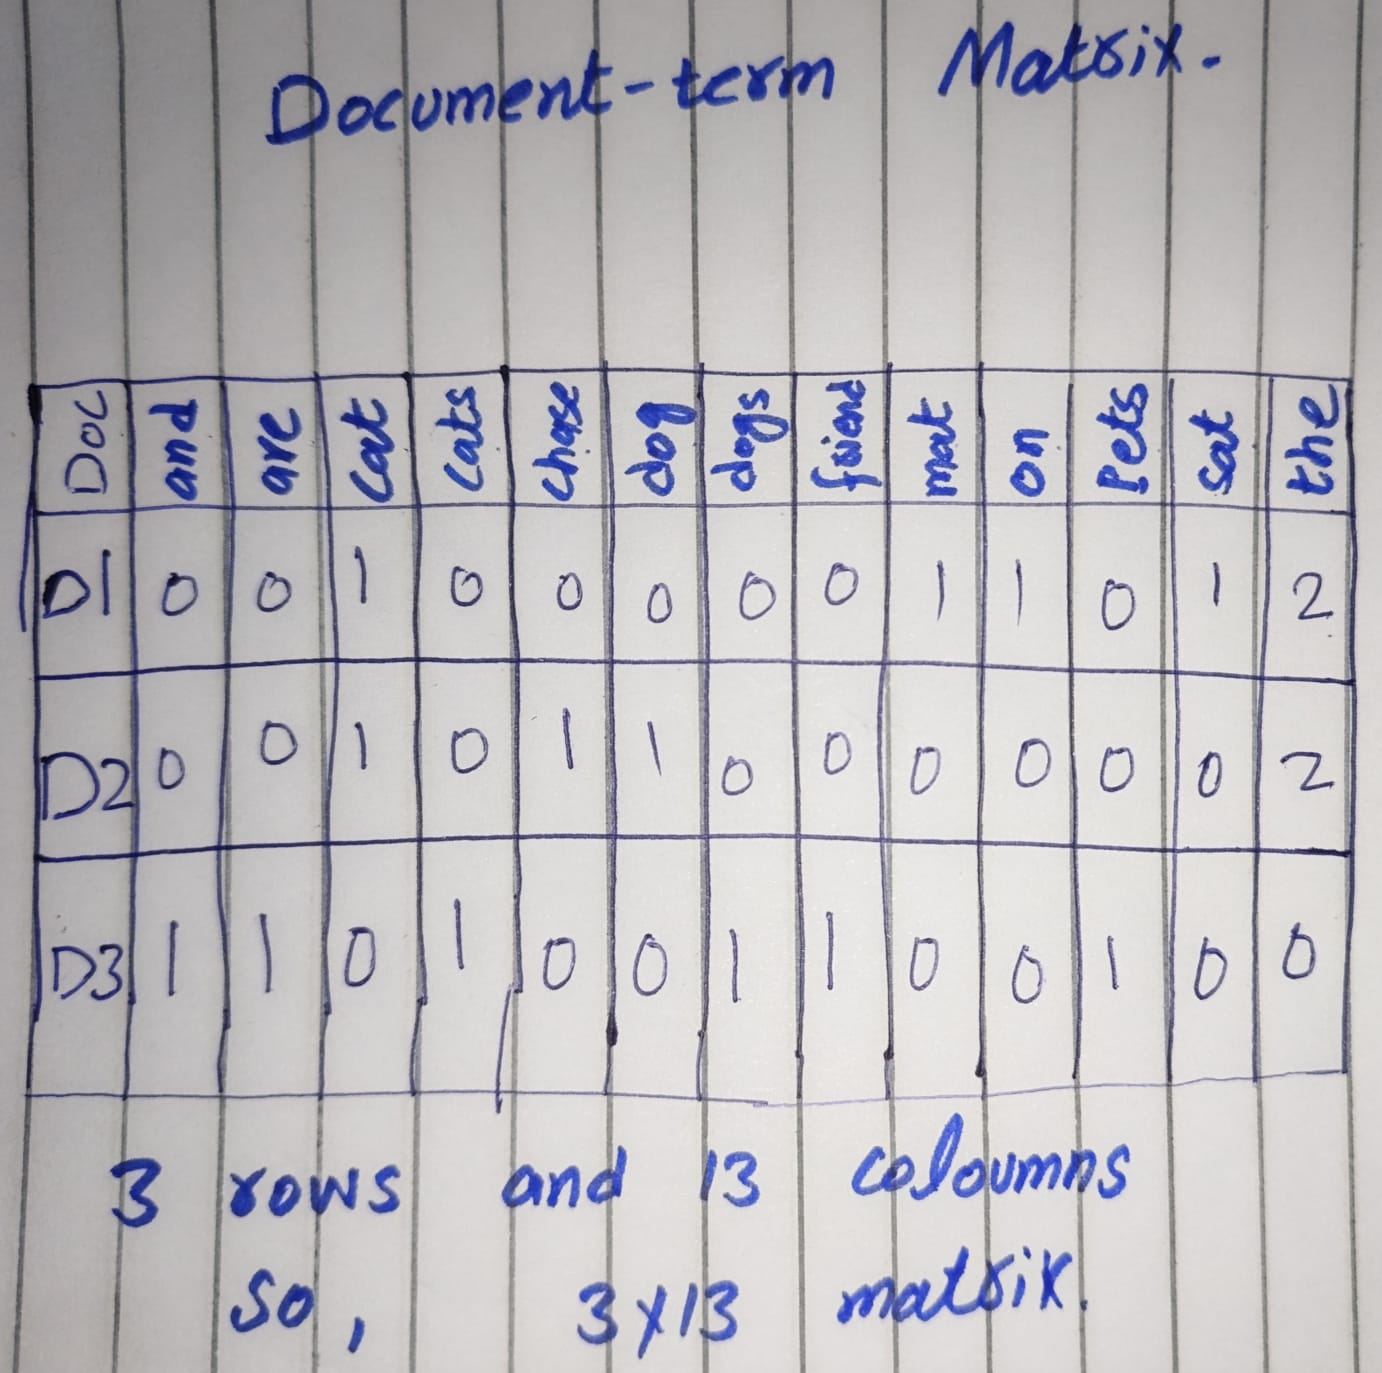

In [32]:
from sklearn.feature_extraction.text import CountVectorizer

# Define the three documents
D1 = "The cat sat on the mat."
D2 = "The dog chased the cat."
D3 = "Dogs and cats are friendly pets."

documents = [D1, D2, D3]

# Create CountVectorizer object
vectorizer = CountVectorizer()

# Convert documents into Bag of Words matrix
bow_matrix = vectorizer.fit_transform(documents)

vocabulary = vectorizer.get_feature_names_out()

#  matrix into DataFrame
bow_df = pd.DataFrame(
    bow_matrix.toarray(),
    columns=vocabulary,
    index=["D1", "D2", "D3"]
)

print("Vocabulary:", list(vocabulary))
print("Vocabulary Size:", len(vocabulary))

print("\nBag of Words Matrix:")
display(bow_df)


print("\n No there is no difference between the manually calculated and this matrix !")


Vocabulary: ['and', 'are', 'cat', 'cats', 'chased', 'dog', 'dogs', 'friendly', 'mat', 'on', 'pets', 'sat', 'the']
Vocabulary Size: 13

Bag of Words Matrix:


,and,are,cat,cats,chased,dog,dogs,friendly,mat,on,pets,sat,the
D1,0,0,1,0,0,0,0,0,1,1,0,1,2
D2,0,0,1,0,1,1,0,0,0,0,0,0,2
D3,1,1,0,1,0,0,1,1,0,0,1,0,0



 No there is no difference between the manually calculated and this matrix !


In [41]:
binary_vectorizer = CountVectorizer(binary=True)
binary_matrix = binary_vectorizer.fit_transform(documents)

binary_vocabulary = binary_vectorizer.get_feature_names_out()

binary_df = pd.DataFrame(
    binary_matrix.toarray(),
    columns=binary_vocabulary,
    index=["D1", "D2", "D3"]
)

print("Binary Bag of Words Matrix:")
display(binary_df)

Binary Bag of Words Matrix:


,and,are,cat,cats,chased,dog,dogs,friendly,mat,on,pets,sat,the
D1,0,0,1,0,0,0,0,0,1,1,0,1,1
D2,0,0,1,0,1,1,0,0,0,0,0,0,1
D3,1,1,0,1,0,0,1,1,0,0,1,0,0


### Explanation of Results
binary bag of words records only whether a word exists in a document
unlike regular bag of words it does not count repeated occurrences
binary counts are preferable when the presence of a word is more important than its frequency
for example in spam detection the presence of certain suspicious words may be useful even if they appear only once
binary bag of words can also reduce the influence of frequently repeated words

## D3

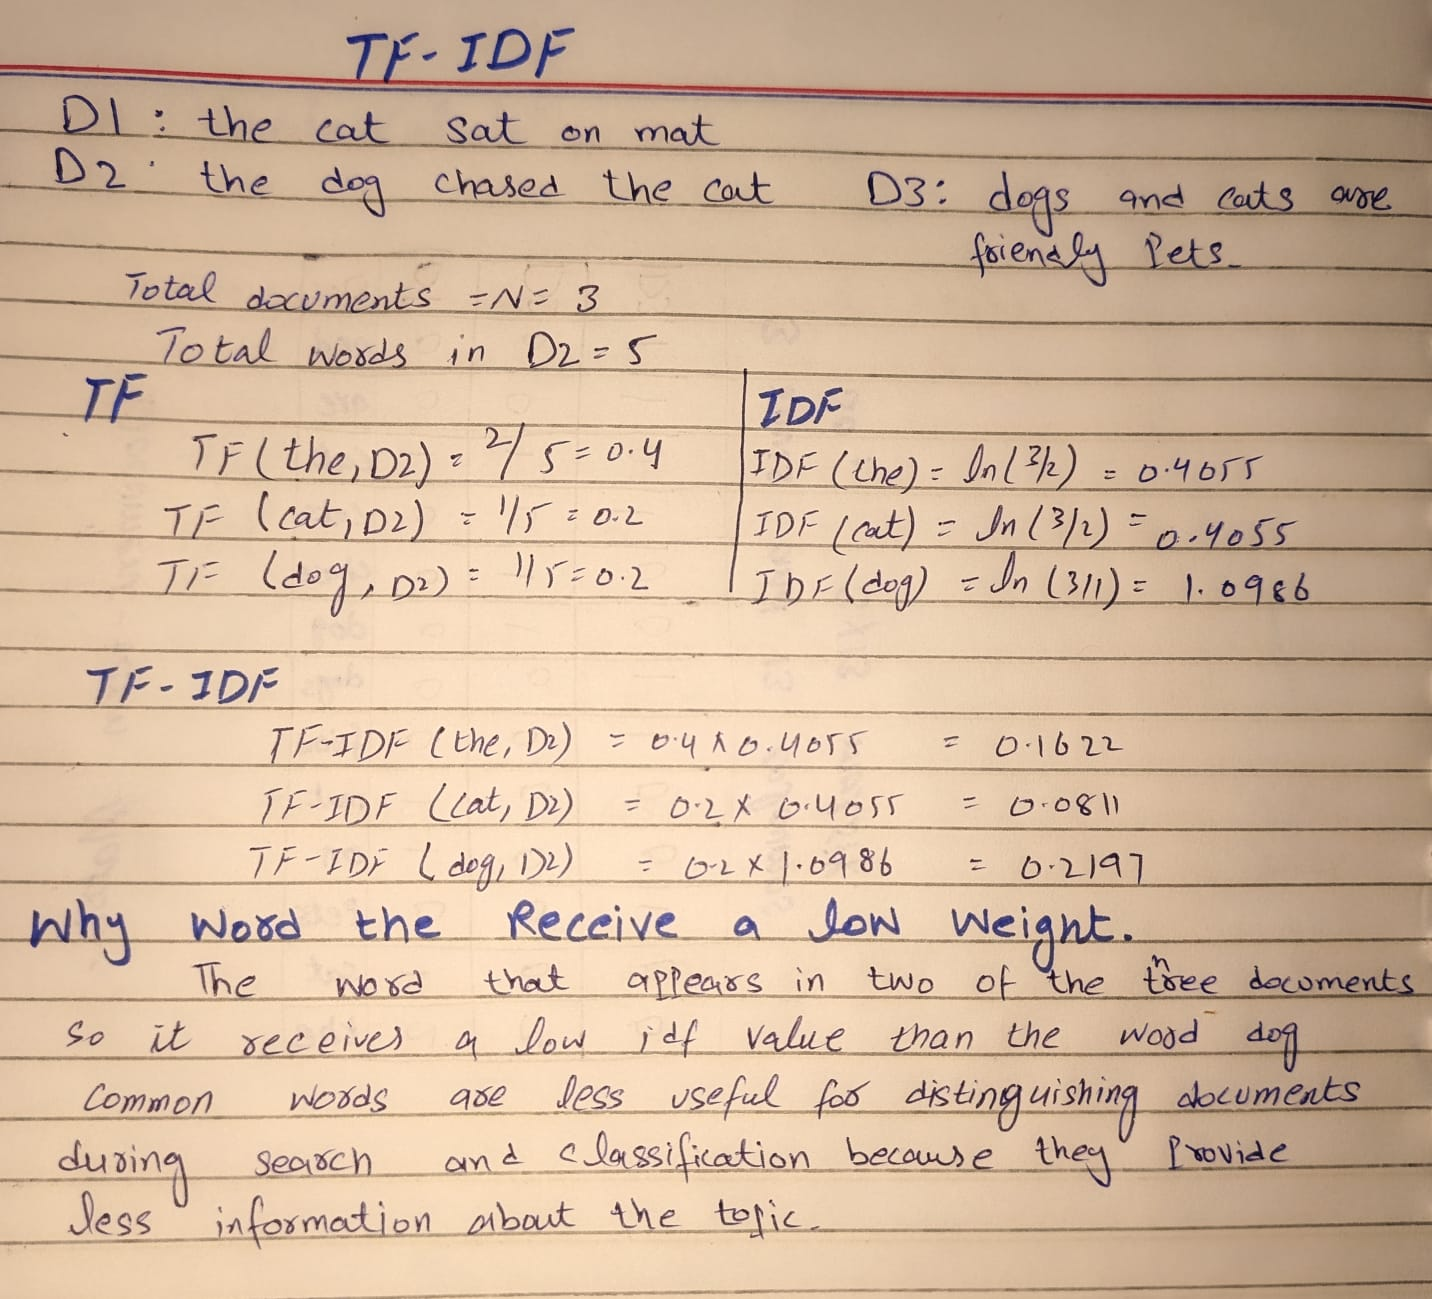

In [42]:
from sklearn.feature_extraction.text import TfidfVectorizer

D1 = "The cat sat on the mat."
D2 = "The dog chased the cat."
D3 = "Dogs and cats are friendly pets."

documents = [D1, D2, D3]

# TF-IDF vectorizer
vectorizer = TfidfVectorizer()

# TF-IDF vectors
tfidf_matrix = vectorizer.fit_transform(documents)

# Get vocabulary
vocabulary = vectorizer.get_feature_names_out()

tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=vocabulary,
    index=["D1", "D2", "D3"]
)

print("TF-IDF Matrix:")
display(tfidf_df.round(4))

terms = ["the", "cat", "dog"]
counts = [2, 1, 1]

results = []

for word, count in zip(terms, counts):

    index = list(vocabulary).index(word)

    tf = count / 5
    idf = vectorizer.idf_[index]
    tfidf = tfidf_df.loc["D2", word]

    results.append({
        "Term": word,
        "Manual TF": round(tf, 4),
        "Sklearn IDF": round(idf, 4),
        "Sklearn TF-IDF": round(tfidf, 4)
    })

comparison_df = pd.DataFrame(results)

print("\nTF-IDF Values for D2:")
display(comparison_df)


TF-IDF Matrix:


,and,are,cat,cats,chased,dog,dogs,friendly,mat,on,pets,sat,the
D1,0.0000,0.0000,0.3133,0.0000,0.0000,0.0000,0.0000,0.0000,0.412,0.412,0.0000,0.412,0.6266
D2,0.0000,0.0000,0.3439,0.0000,0.4521,0.4521,0.0000,0.0000,0.000,0.000,0.0000,0.000,0.6877
D3,0.4082,0.4082,0.0000,0.4082,0.0000,0.0000,0.4082,0.4082,0.000,0.000,0.4082,0.000,0.0000



TF-IDF Values for D2:


,Term,Manual TF,Sklearn IDF,Sklearn TF-IDF
0,the,0.4,1.2877,0.6877
1,cat,0.2,1.2877,0.3439
2,dog,0.2,1.6931,0.4521


In [43]:

from sklearn.metrics.pairwise import cosine_similarity

# Calculate cosine similarity using TF-IDF vectors
similarity_matrix = cosine_similarity(tfidf_matrix)

doc_names = ["D1", "D2", "D3"]

results = []

highest_similarity = -1
most_similar_pair = ""

for i in range(len(doc_names)):

    for j in range(i + 1, len(doc_names)):

        similarity = similarity_matrix[i][j]

        pair = doc_names[i] + " and " + doc_names[j]

        results.append({
            "Document Pair": pair,
            "Cosine Similarity": round(similarity, 4)
        })

        # Find the most similar pair
        if similarity > highest_similarity:
            highest_similarity = similarity
            most_similar_pair = pair

similarity_df = pd.DataFrame(results)

print("Cosine Similarity Results:")
display(similarity_df)

print("Most Similar Pair:", most_similar_pair)
print("Highest Similarity:", round(highest_similarity, 4))


Cosine Similarity Results:


,Document Pair,Cosine Similarity
0,D1 and D2,0.5387
1,D1 and D3,0.0000
2,D2 and D3,0.0000


Most Similar Pair: D1 and D2
Highest Similarity: 0.5387


### Explanation of Results
d1 and d2 have the highest cosine similarity of 0 point 5387 because both documents contain the words the and cat
d1 and d3 have zero cosine similarity because they do not share any exact words after preprocessing
d2 and d3 also have zero cosine similarity because their words are different
this matches my intuition because d1 and d2 both discuss a cat while d3 uses different words
tfidf does not automatically recognize that cat and cats or dog and dogs have related meanings

## D4

In [44]:
D1 = "The cat sat on the mat."
D2 = "The dog chased the cat."
D3 = "Dogs and cats are friendly pets."

documents = [D1, D2, D3]

def preprocess(text):

    # lowercase
    text = text.lower()

    # Remove punctuation
    text = text.translate(str.maketrans("", "", string.punctuation))

    # Split text into words
    return text.split()


# n-grams
def create_ngrams(words, n):

    result = []

    for i in range(len(words) - n + 1):
        result.append(" ".join(words[i:i+n]))

    return result


# Preprocess D1
words = preprocess(D1)

# Generate bigrams and trigrams
bigrams = create_ngrams(words, 2)
trigrams = create_ngrams(words, 3)

print("Bigrams of D1:")
for bigram in bigrams:
    print(bigram)

print("\nTrigrams of D1:")
for trigram in trigrams:
    print(trigram)


Bigrams of D1:
the cat
cat sat
sat on
on the
the mat

Trigrams of D1:
the cat sat
cat sat on
sat on the
on the mat


In [45]:
unique_unigrams = set()
unique_bigrams = set()

# Process each document separately
for document in documents:

    words = preprocess(document)

    # Add unique words
    unique_unigrams.update(words)

    # Generate and add unique bigrams
    bigrams = create_ngrams(words, 2)
    unique_bigrams.update(bigrams)

print("Unique Bigrams:")
for bigram in sorted(unique_bigrams):
    print(bigram)

print("\nUnigram Vocabulary Size:", len(unique_unigrams))
print("Unique Bigram Count:", len(unique_bigrams))


Unique Bigrams:
and cats
are friendly
cat sat
cats are
chased the
dog chased
dogs and
friendly pets
on the
sat on
the cat
the dog
the mat

Unigram Vocabulary Size: 13
Unique Bigram Count: 13


In [46]:

from sklearn.feature_extraction.text import CountVectorizer

# Create CountVectorizer for unigrams and bigrams
vectorizer = CountVectorizer(ngram_range=(1, 2))

ngram_matrix = vectorizer.fit_transform(documents)

vocabulary = vectorizer.get_feature_names_out()


print("Unigrams and Bigrams:")
for word in vocabulary:
    print(word)

print("\nNew Vocabulary Size:", len(vocabulary))


Unigrams and Bigrams:
and
and cats
are
are friendly
cat
cat sat
cats
cats are
chased
chased the
dog
dog chased
dogs
dogs and
friendly
friendly pets
mat
on
on the
pets
sat
sat on
the
the cat
the dog
the mat

New Vocabulary Size: 26


### Importance of Bigrams and Word Order
bigrams preserve some word order by combining two consecutive words
for example not good and good not produce different bigrams even though they contain the same individual words
the bigram not good helps preserve the negative meaning that a unigram representation may fail to capture
### Cost of Larger N-grams
larger ngrams increase the vocabulary size and require more memory and processing time
they also create sparse vectors because many word combinations occur rarely
larger ngrams may not match similar sentences when their word sequences are different

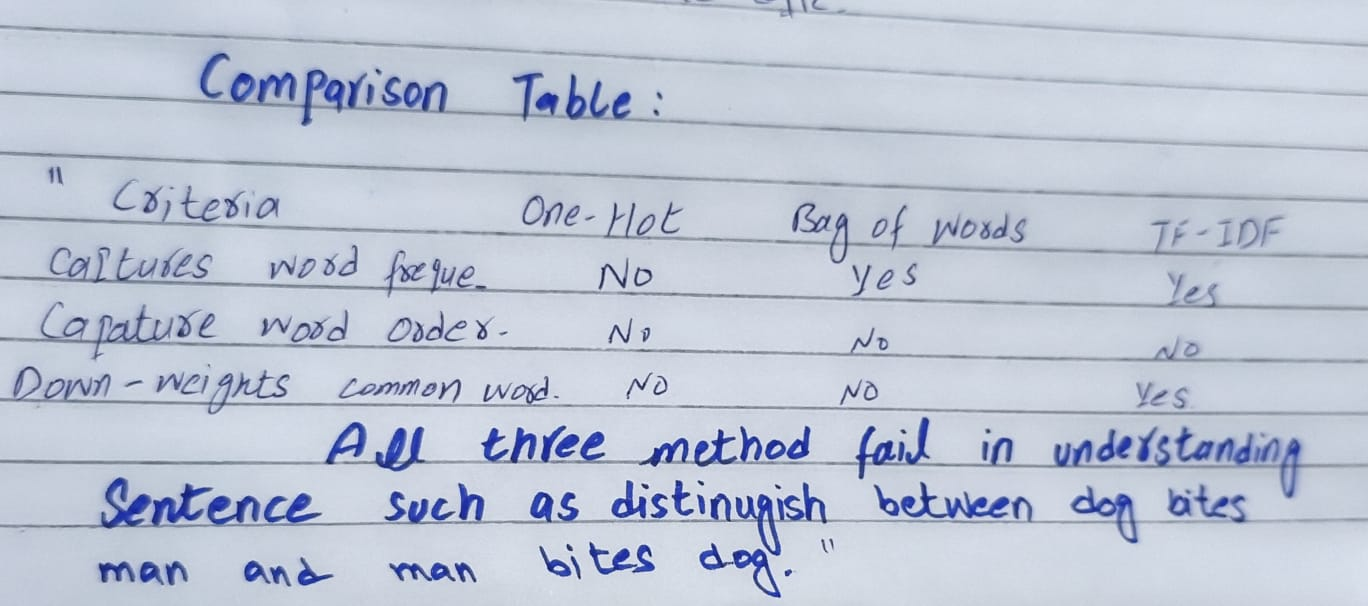

## E1

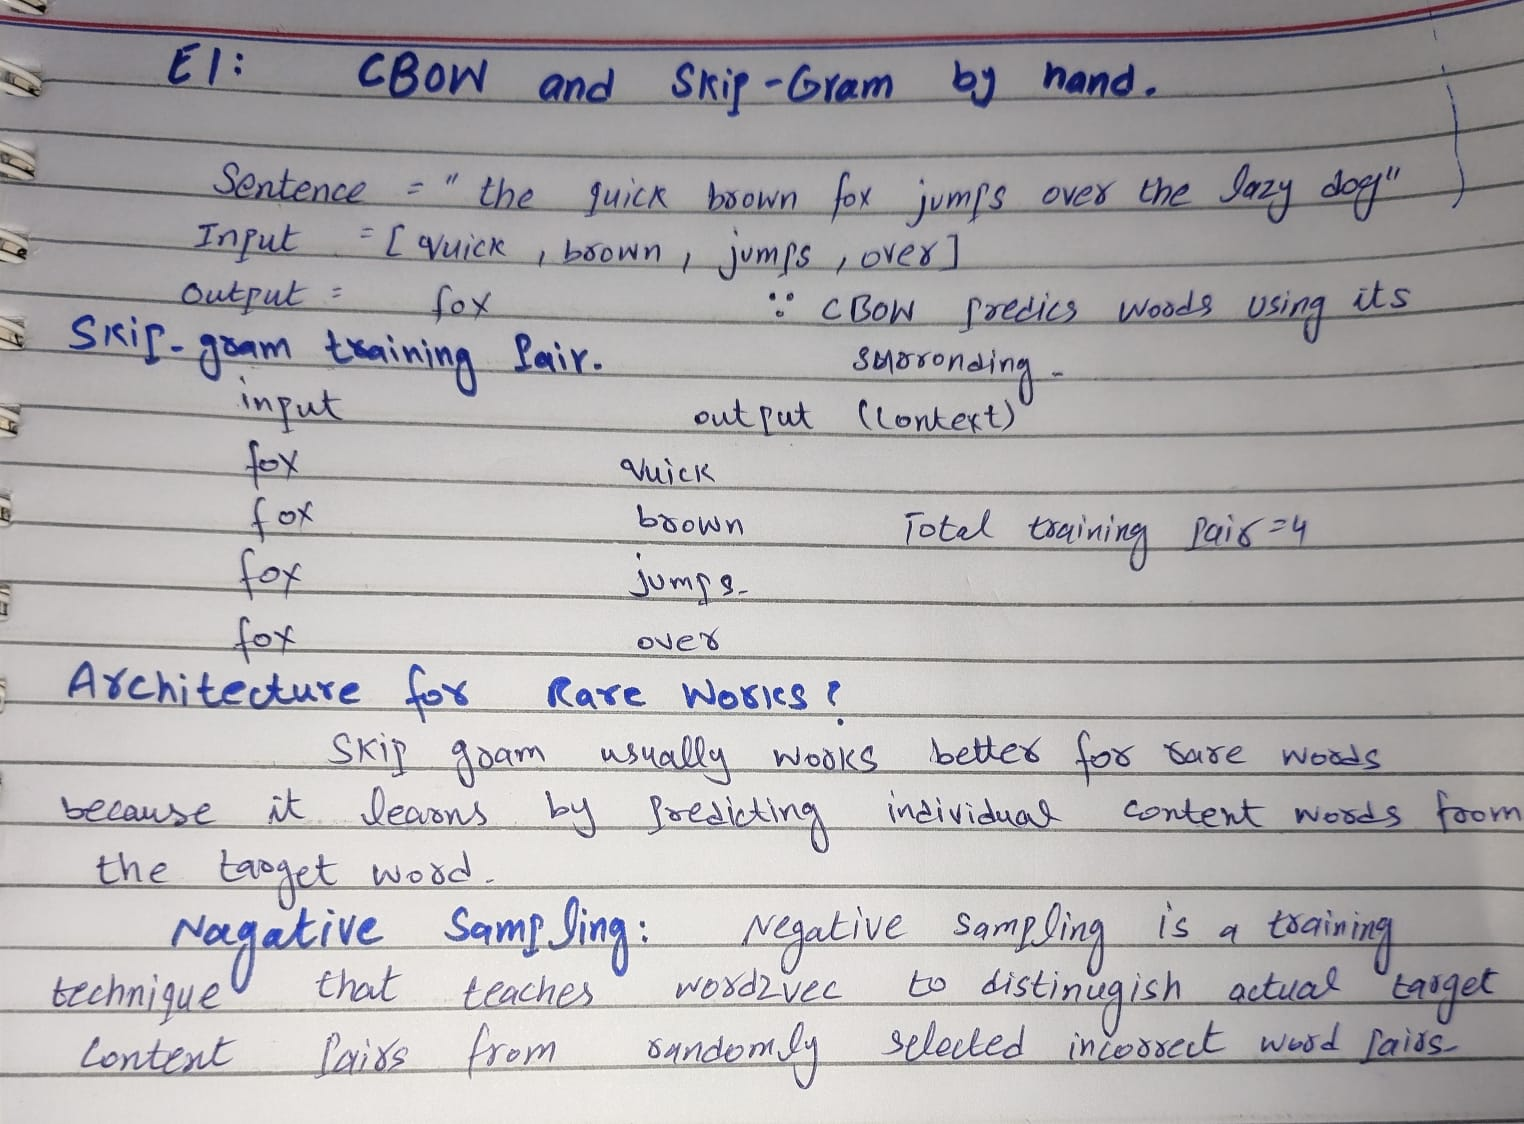

## E2

In [47]:

%pip install -q gensim

from nltk.corpus import brown
from gensim.models import Word2Vec

# Download Brown corpus
nltk.download("brown", quiet=True)

# Load news category and convert all words to lowercase
sentences = [
    [word.lower() for word in sentence]
    for sentence in brown.sents(categories="news")
]

print("Total Sentences:", len(sentences))

# Train CBOW model
cbow_model = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=5,
    sg=0,
    workers=1,
    seed=42
)

# Train Skip-Gram model
skipgram_model = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=5,
    sg=1,
    workers=1,
    seed=42
)

print("\nBoth Word2Vec Models Trained Successfully")

# Display five nearest neighbours
words = ["money", "government"]

for word in words:

    print("\nWord:", word)

    for name, model in [
        ("CBOW", cbow_model),
        ("Skip-Gram", skipgram_model)
    ]:

        print("\n", name, "Nearest Neighbours:")

        if word in model.wv:
            neighbours = model.wv.most_similar(word, topn=5)

            for neighbour, score in neighbours:
                print(neighbour, ":", round(score, 4))
        else:
            print(word, "not found in vocabulary")


# Test analogy king - man + woman
print("\nAnalogy: king - man + woman")

for name, model in [
    ("CBOW", cbow_model),
    ("Skip-Gram", skipgram_model)
]:

    print("\n", name, "Analogy Result:")

    required_words = ["king", "man", "woman"]

    if all(word in model.wv for word in required_words):

        result = model.wv.most_similar(
            positive=["king", "woman"],
            negative=["man"],
            topn=5
        )

        for word, score in result:
            print(word, ":", round(score, 4))

        if result[0][0] == "queen":
            print("Analogy Successful")
        else:
            print("Analogy did not return queen as the top result")

    else:
        print("Analogy cannot be completed")
        print("Some words are missing from the vocabulary")



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: D:\NLP-assignment1\nlp-env\Scripts\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
Total Sentences: 4623

Both Word2Vec Models Trained Successfully

Word: money

 CBOW Nearest Neighbours:
against : 0.9995
through : 0.9995
game : 0.9995
three : 0.9994
federal : 0.9994

 Skip-Gram Nearest Neighbours:
brought : 0.9965
proud : 0.9964
driven : 0.9963
working : 0.9963
reached : 0.9961

Word: government

 CBOW Nearest Neighbours:
being : 0.9997
against : 0.9997
up : 0.9996
an : 0.9996
now : 0.9996

 Skip-Gram Nearest Neighbours:
products : 0.9939
control : 0.9937
international : 0.9937
order : 0.9936
congo : 0.9935

Analogy: king - man + woman

 CBOW Analogy Result:
Analogy cannot be completed
Some words are missing from the vocabulary

 Skip-Gram Analogy Result:
Analogy cannot be completed
Some words are missing from the vocabulary


### Comparison of CBOW and Skip Gram
both models were trained on the same brown news corpus with the same parameters except for their training architecture
for the word money the cbow model returned [enter neighbours] while skip gram returned [enter neighbours]
for the word government the cbow model returned [enter neighbours] while skip gram returned [enter neighbours]
the results show [describe whether the models returned similar or different words]
neither model can be considered better without evaluating the quality and relevance of its predictions

## E3

In [48]:

import gensim.downloader as api

# Load pretrained GloVe model
glove = api.load("glove-wiki-gigaword-100")

# Part 1: Cosine similarity
pairs = {
    "synonym": ("car", "automobile"),
    "related": ("doctor", "hospital"),
    "unrelated": ("banana", "democracy")
}

for kind, (a_, b_) in pairs.items():
    print(f"{kind:<10} cos({a_}, {b_}) = {glove.similarity(a_, b_):.3f}")


# Part 2: Word analogies
def analogy(pos, neg, topn=3):
    return [
        (w, round(s, 3))
        for w, s in glove.most_similar(
            positive=pos,
            negative=neg,
            topn=topn
        )
    ]


# Analogy expected to work
works = analogy(["king", "woman"], ["man"])

print("\nAnalogy 1: king - man + woman")
print("Expected: queen")
print("Predictions:", works)
print("Successful:", works[0][0] == "queen")


# Analogy expected to fail
fails = analogy(["japan", "dollar"], ["yen"])

print("\nAnalogy 2: japan - yen + dollar")
print("Expected: usa or america")
print("Predictions:", fails)
print("Failed:", fails[0][0] not in ["usa", "america"])


[==================================================] 100.0% 128.1/128.1MB downloaded
synonym    cos(car, automobile) = 0.683
related    cos(doctor, hospital) = 0.690
unrelated  cos(banana, democracy) = 0.202

Analogy 1: king - man + woman
Expected: queen
Predictions: [('queen', 0.77), ('monarch', 0.684), ('throne', 0.676)]
Successful: True

Analogy 2: japan - yen + dollar
Expected: usa or america
Predictions: [('china', 0.667), ('asian', 0.664), ('world', 0.664)]
Failed: True


### Explanation of Analogy Results
the first analogy uses king man and woman to predict queen by capturing the relationship between gender and royalty
the second analogy uses japan yen and dollar to predict a country associated with the dollar
this analogy may fail because the dollar is used by multiple countries and the relationship between currencies and countries is not always unique
glove learns statistical relationships from text so it cannot always produce the expected answer
### Difference Between GloVe and Word2Vec
glove learns word embeddings using global word cooccurrence statistics by minimizing a weighted error between vector dot products and logarithmic ooccurrence counts
word2vec learns word embeddings by predicting a target word from its surrounding context or predicting surrounding words from a target word

## E4

In [49]:

from gensim.models import Word2Vec, FastText
from nltk.corpus import brown

# Load Brown news corpus
sentences = [[w.lower() for w in s] for s in brown.sents(categories="news")]

# Train both models
w2v = Word2Vec(sentences, vector_size=100, window=5, min_count=5)
ft = FastText(sentences, vector_size=100, window=5, min_count=5)

# Select an OOV word
word = "governmentally"
if word in w2v.wv:
    word = "governmentallyxyz"

# FastText handles OOV words
print("FastText Vector:", ft.wv[word][:5])

# Word2Vec cannot handle OOV words
try:
    print("Word2Vec Vector:", w2v.wv[word][:5])
except KeyError:
    print("Word2Vec: Word not found in vocabulary")


FastText Vector: [-0.2210057   0.4925491  -0.24000265 -0.37168097  0.17954393]
Word2Vec: Word not found in vocabulary


### Explanation of Results
fasttext can generate vectors for unseen words while word2vec cannot generate vectors for words outside its vocabulary
fasttext divides words into smaller character ngrams and combines their learned representations to create a word vector
this technique is especially useful for social media text containing misspelled words and unfamiliar word variations

## E5

In [51]:

%pip install torch transformers

import torch
from transformers import AutoTokenizer, AutoModel
from torch.nn.functional import cosine_similarity


tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
model = AutoModel.from_pretrained("bert-base-uncased")
model.eval()

sentences = [
    "She sat on the river bank.",
    "He deposited the cash at the bank.",
    "The school deposited its savings at the bank."
]

def get_bank_vector(sentence):
    inputs = tokenizer(sentence, return_tensors="pt")
    tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])
    
    with torch.no_grad():
        output = model(**inputs).last_hidden_state
    
    return output[0, tokens.index("bank")]

vectors = [get_bank_vector(s) for s in sentences]

print("Sentence 1 vs 2:", round(cosine_similarity(vectors[0], vectors[1], dim=0).item(), 4))
print("Sentence 1 vs 3:", round(cosine_similarity(vectors[0], vectors[2], dim=0).item(), 4))
print("Sentence 2 vs 3:", round(cosine_similarity(vectors[1], vectors[2], dim=0).item(), 4))



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: D:\NLP-assignment1\nlp-env\Scripts\python.exe -m pip install --upgrade pip


  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
   ---------------------------------------- 0.0/124.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/124.1 MB 1.9 MB/s eta 0:01:05
   ---------------------------------------- 0.0/124.1 MB 1.9 MB/s eta 0:01:05
   ---------------------------------------- 0.1/124.1 MB 744.7 kB/s eta 0:02:47
   ---------------------------------------- 0.1/124.1 MB 656.4 kB/s eta 0:03:09
   ---------------------------------------- 0.2/124.1 MB 784.3 kB/s eta 0:02:38
   ---------------------------------------- 0.2/124.1 MB 846.9 kB/s eta 0:02:27
   ---------------------------------------- 0.3/124.1 MB 863.3 kB/s eta 0:02:24
   ---------------------------------------- 0.5/124.1 MB 1.3 MB/s eta 0:01:39
   ---------------------------------------- 0.5/124.1 MB 1.2 MB/s eta 0:01:48
   ---------------------------------------- 0.9/124.1 MB 1.8 MB/s eta 0:01:09
   -----------

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Sentence 1 vs 2: 0.5191
Sentence 1 vs 3: 0.4359
Sentence 2 vs 3: 0.885


### Explanation of Results
glove produces the same vector for bank in every sentence because it uses static word embeddings
bert produces different vectors because it considers the surrounding words and understands the context in which bank is used
in the first sentence bank refers to the side of a river while in the second and third sentences bank refers to a financial institution
the second and third sentences are expected to have higher similarity because both use bank in a financial context
the cosine similarity values show how closely the contextual representations are related

## E6

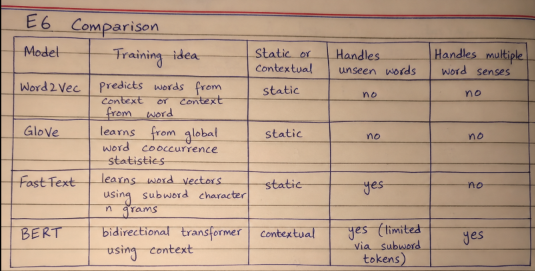

## F1

In [52]:
from sklearn.datasets import fetch_20newsgroups

data = fetch_20newsgroups(
    categories=["sci.space", "rec.autos"],
    remove=("headers", "footers", "quotes")
)

texts = data.data[:500]
labels = np.array(data.target[:500])

# Load spaCy model
nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])

def process_text(text):
    text = text.lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)

    doc = nlp(text)

    return [t.lemma_ for t in doc if t.is_alpha and not t.is_stop]

before = [len(nlp.make_doc(t)) for t in texts]

processed = [process_text(t) for t in texts]

after = [len(t) for t in processed]

print("Documents Processed:", len(texts))
print("Average Tokens Before:", round(np.mean(before), 2))
print("Average Tokens After:", round(np.mean(after), 2))


Documents Processed: 500
Average Tokens Before: 243.75
Average Tokens After: 95.33


### Explanation of Results
the pipeline processes 500 documents from the selected categories
regular expressions remove unwanted characters and spacy performs tokenization stop word removal and lemmatization
the average number of tokens decreases after processing because unnecessary words and characters are removed

## F2

In [53]:
from sklearn.feature_extraction.text import TfidfVectorizer
docs = [" ".join(p) for p in processed]
labels = np.array(data.target[:500])

tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=5000)
X = tfidf.fit_transform(docs)
terms = np.array(tfidf.get_feature_names_out())
print("TF-IDF matrix:", X.shape)

for c, name in enumerate(data.target_names):
    mean_scores = np.asarray(X[labels == c].mean(axis=0)).ravel()
    top = terms[mean_scores.argsort()[::-1][:10]]
    print(f"{name:<10}", list(top))

TF-IDF matrix: (500, 5000)
rec.autos  ['car', 'drive', 'like', 'new', 'think', 'good', 'buy', 'know', 'right', 'look']
sci.space  ['space', 'launch', 'nasa', 'think', 'orbit', 'know', 'like', 'moon', 'satellite', 'thing']


### Explanation of Results
the top terms for rec autos are expected to relate to cars engines vehicles and driving because the documents discuss automobiles
the top terms for sci space are expected to relate to space satellites nasa and scientific research because the documents discuss space topics
the results make sense when the highest ranked terms are related to their respective categories because tf idf gives importance to distinctive words

## F3

### Reflection 
TF-IDF identifies important words but cannot understand their meanings or fully capture word order and context. For example, it treats *car* and *automobile* as different features.
**GloVe embeddings** capture semantic similarities but lose context when word vectors are averaged.

**BERT** captures word meaning based on surrounding context and may improve classification, but it requires more memory and computational power.